#### Text-based segmentation using `OWLv2`+`SAM2`

In [1]:
from package.init_scripts.init_ipython_setup import *
from package.init_scripts.init_qt import *
from package.utility import *
from package.hf_models import *

[qt] package initialized.
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.


In [2]:
# Prompt-based detection with owlv2
owl = PromptOwlv2(
    ckpt      = "google/owlv2-base-patch16",
    local_dir = "../hf_models/owlv2",
    verbose   = True,
)
# Point-based segmentation with SAM2
sam2 = PointSam2(
    ckpt      = "facebook/sam2.1-hiera-base-plus",
    local_dir = "../hf_models/sam2",
    verbose   = True,
)
# Prompt-based segmentation with owlv2 and SAM2
seg = PromptOwlv2Sam2(
    owl     = owl,
    sam2    = sam2,
    verbose = True,
)

[ensure_local_ckpt] found local_dir:[../hf_models/owlv2]
Using [MPS] device


Loading weights: 100%|██████████| 418/418 [00:00<00:00, 5783.53it/s]


[PromptOwlv2] ckpt=[../hf_models/owlv2] ready.
[ensure_local_ckpt] found local_dir:[../hf_models/sam2]


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Using [MPS] device


Loading weights: 100%|██████████| 453/453 [00:00<00:00, 6636.88it/s]


[PointSam2] ckpt=[../hf_models/sam2] ready.


[imread] Loaded image from [../imgs/cluttered_desk.jpg] with shape (512, 768, 3) dtype=uint8


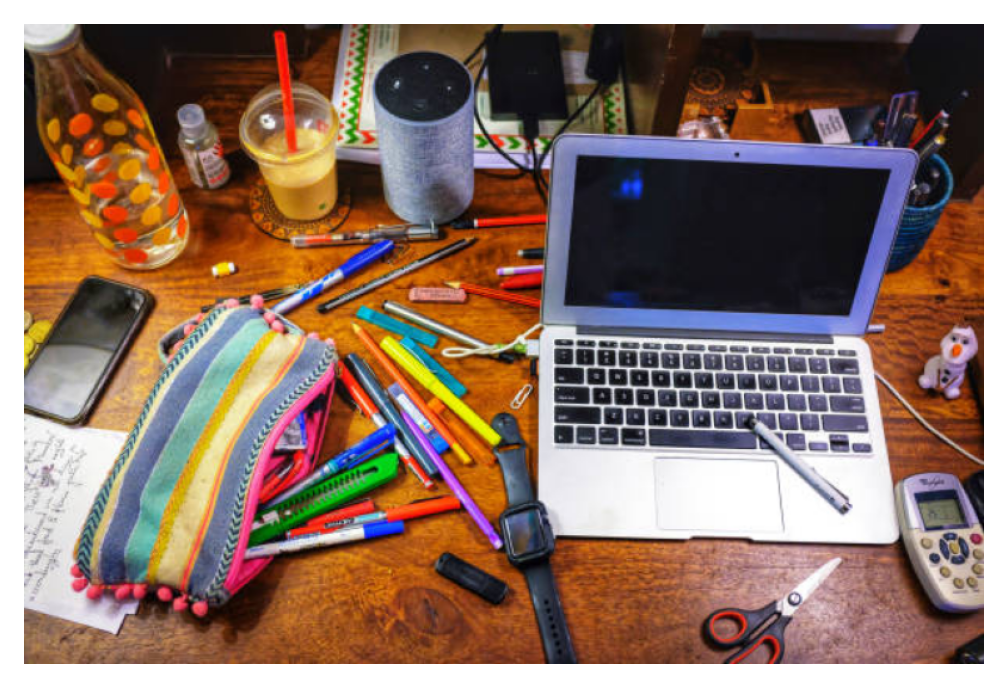

In [3]:
# Load image
impath = "../imgs/cluttered_desk.jpg"
img_np,img_pil = imread(
    impath,
    return_np  = True,
    return_pil = True,
    show_image = True,
    fig_w      = 4,
    out_h      = 512,
)
h,w = img_np.shape[:2]

In [4]:
# Run text-based segmentation
text_queries = ["Pen"]
results = seg.run(
    img_pil,
    text_queries      = text_queries,
    det_threshold     = 0.1,
    topk_per_query    = 2,
    use_neg_points    = False,
    fill_holes        = True,
    keep_largest      = True,
    overlay_alpha     = 0.5,
)

[PromptOwlv2Sam2] queries:1, det_threshold:0.100, results:2


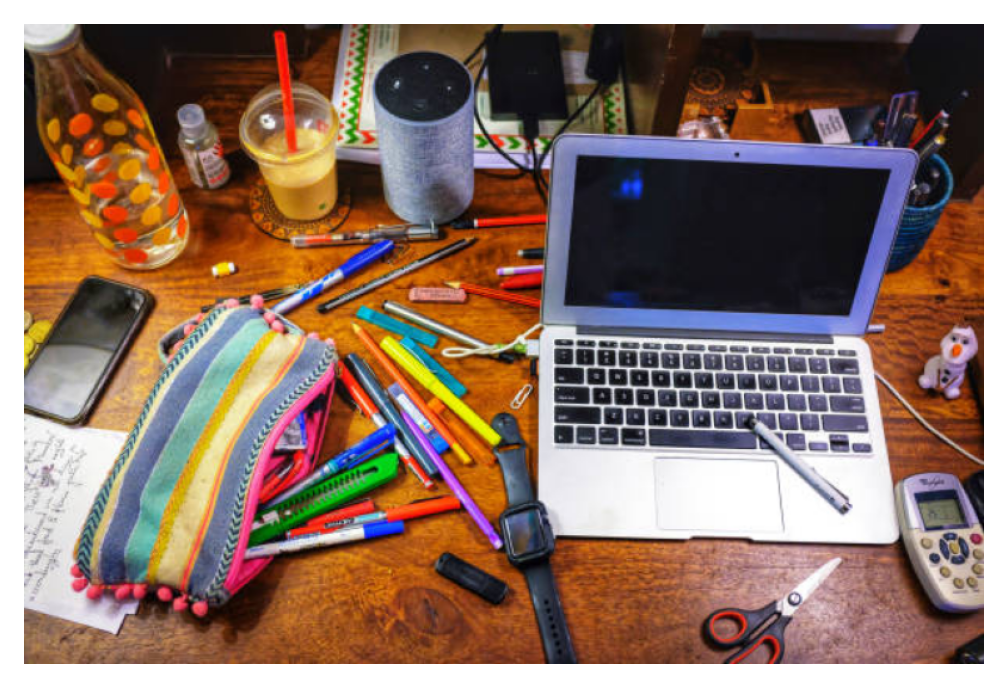

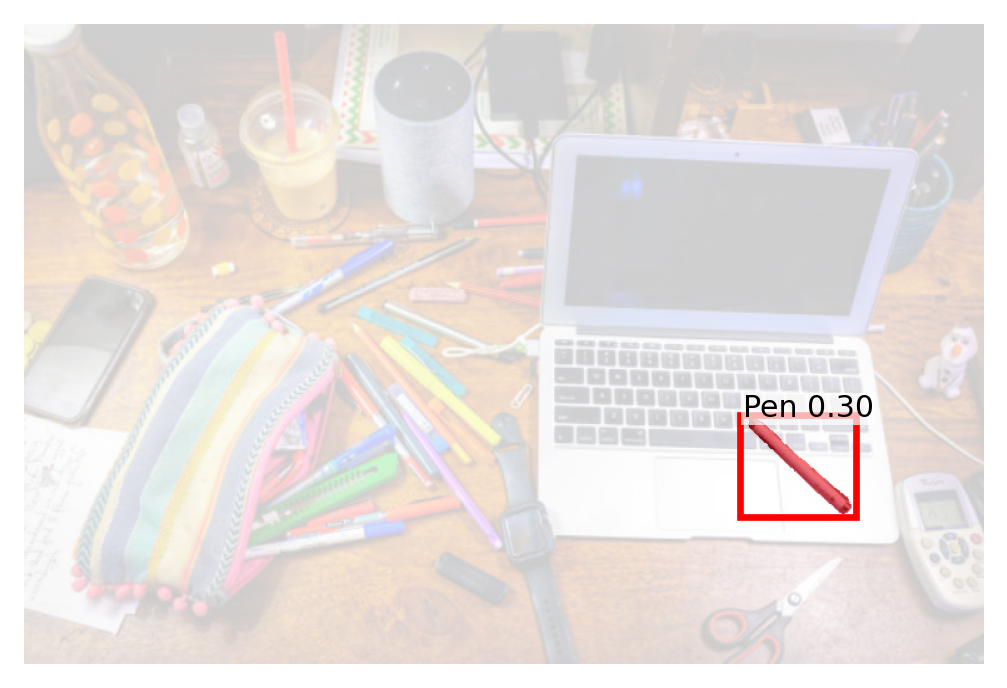

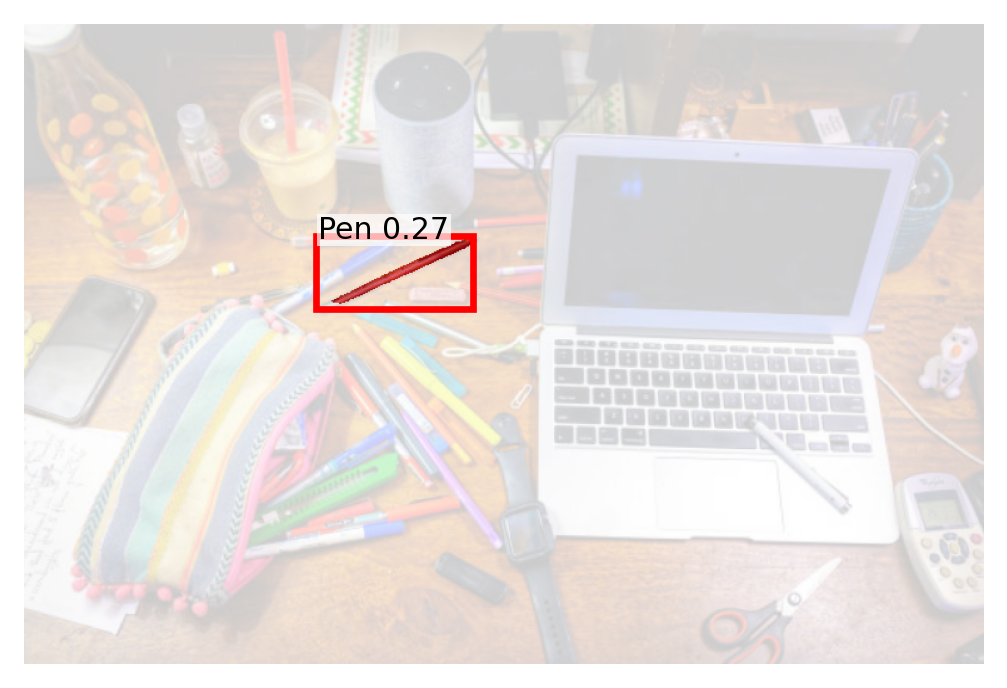

In [5]:
imshow(img_np,fig_w=4)
seg.plot_det_seg(
    img_np  = img_np,
    results = results,
    fig_w   = 4,
    overlay_bright = 0.8,
)